# P19: where does the final model look? (Grad-CAM)

The final model says "portrait" or "cityscape", but from what? It could look at faces and buildings, or at shortcuts: the frame,
a signature in a corner, the dark background of old paintings. **Grad-CAM** answers per painting: it takes the 512 maps of 7 x 7
cells that the last block (`layer4`) produces, weights each map by the mean gradient of the predicted genre's score with respect
to it, sums them and keeps the positive part. The result is a 7 x 7 grid: how much each region of the painting pushed towards
the predicted genre. It is built here from PyTorch hooks, no library.

**The paintings are never shown** (licence, as in P10): every result below is a statistic over many paintings. A flag at the end
draws a few paintings with their map, off by default, and its outputs must not be committed.

**The rules, fixed before any result** (a scratch run, unsaved, checked the code):

- The final model (ADR 0012), unchanged; the 480 validation paintings only (museum B is not used).
- Each map is normalised to sum to 1, so it says where the decision comes from, not how strong it is.
- **Is the map faithful?** For each painting, its 10 most important cells (of 49, each 32 x 32 pixels) are painted grey, and
  the accuracy measured; then 10 random cells (seeded), then the 10 least important. If the map is faithful, hiding the most
  important cells hurts far more than hiding random ones.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import WALL, final_model, predict_logits, split_images, to_tensor

model = final_model()
LAYER4 = model[7]  # final_model() is conv1, bn1, relu, maxpool, layer1, layer2, layer3, then layer4 and the final layer
classes = ["cityscape", "landscape", "portrait", "religious_painting", "still_life"]
val_images, y_val = split_images("val")


def grad_cam(images, batch_size=40):
    """Grad-CAM of the predicted genre for each PIL image: (n, 7, 7) maps that sum to 1, and the predicted genres."""
    saved = {}

    def keep(module, inputs, output):
        output.retain_grad()  # the gradient of the score with respect to the maps of layer4
        saved["maps"] = output

    handle = LAYER4.register_forward_hook(keep)
    maps, predicted = [], []
    try:
        for i in range(0, len(images), batch_size):
            model.zero_grad()
            scores = model(to_tensor(images[i:i + batch_size]))
            top = scores.argmax(dim=1)
            scores.gather(1, top[:, None]).sum().backward()  # each painting's own predicted score
            activations, gradients = saved["maps"], saved["maps"].grad
            weights = gradients.mean(dim=(2, 3), keepdim=True)  # one weight per map: its mean gradient
            cam = torch.relu((weights * activations).sum(dim=1)).detach()
            maps.append(cam / cam.sum(dim=(1, 2), keepdim=True).clamp_min(1e-12))
            predicted.append(top)
    finally:
        handle.remove()
    return torch.cat(maps), torch.cat(predicted)


cams, predicted = grad_cam(val_images)
correct = predicted == y_val
print(f"{len(cams)} maps of {tuple(cams.shape[1:])}; validation accuracy {correct.float().mean():.1%} (ADR 0012: 83.3%)")

480 maps of (7, 7); validation accuracy 83.3% (ADR 0012: 83.3%)


## 1. Where the model looks, genre by genre

The mean map of the paintings each genre was correctly predicted for, and the share of the decision that comes from the outer
ring of cells (24 of the 49 cells, 49% of the surface: frame, edges, corners) and from the 3 x 3 centre (18% of the surface).

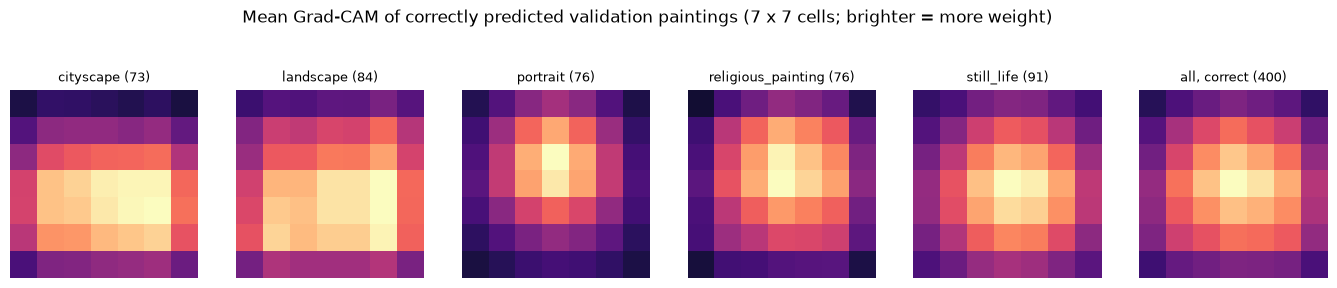

,paintings,share from the outer ring,share from the centre,largest cell (mean)
genre,,,,
cityscape,73.0,0.317,0.277,0.056
landscape,84.0,0.344,0.246,0.049
portrait,76.0,0.269,0.350,0.061
religious_painting,76.0,0.262,0.317,0.060
still_life,91.0,0.324,0.298,0.047
"all, correct",400.0,0.305,0.297,0.054
uniform map (reference),NaN,0.490,0.184,0.020


In [2]:
ring = torch.ones(7, 7, dtype=torch.bool)
ring[1:6, 1:6] = False
centre = torch.zeros(7, 7, dtype=torch.bool)
centre[2:5, 2:5] = True
rows = []
fig, axes = plt.subplots(1, 6, figsize=(17, 3.2))
for k, genre in enumerate(classes + ["all, correct"]):
    keep = correct & (y_val == k) if k < 5 else correct
    mean_map = cams[keep].mean(dim=0)
    axes[k].imshow(mean_map, cmap="magma", vmin=0)
    axes[k].set_title(f"{genre} ({keep.sum().item()})", fontsize=9)
    axes[k].axis("off")
    rows.append({"genre": genre, "paintings": keep.sum().item(), "share from the outer ring": cams[keep][:, ring].sum(1).mean().item(),
                 "share from the centre": cams[keep][:, centre].sum(1).mean().item(),
                 "largest cell (mean)": cams[keep].flatten(1).max(1).values.mean().item()})
fig.suptitle("Mean Grad-CAM of correctly predicted validation paintings (7 x 7 cells; brighter = more weight)", y=1.04)
plt.show()
uniform = {"genre": "uniform map (reference)", "paintings": np.nan, "share from the outer ring": 24 / 49,
           "share from the centre": 9 / 49, "largest cell (mean)": 1 / 49}
pd.DataFrame(rows + [uniform]).set_index("genre").round(3)

**What we see.**

- **No frame or corner shortcut.** Only 30.5% of the decision comes from the outer ring of cells, which covers 49% of the painting; the 3 x 3 centre, 18% of the surface, gives 29.7%. The corners are among the darkest cells of every mean map.
- **Each genre has its own place, and it is the expected one.** Cityscapes and landscapes are decided from a wide horizontal band in the lower half (the ground, the buildings, the horizon), not from the sky. Portraits and religious paintings are decided from the upper centre, where a face usually is (portraits: 35% of the decision from the centre, the most concentrated maps). Still lifes from the centre of the canvas, where the objects are.
- These are means over 73 to 91 paintings: a single painting's map is far patchier (its largest cell holds 5.4% of the decision on average, 2.7 times a uniform cell).

## 2. Is the map faithful? Hiding the cells it points to

In [3]:
rng = np.random.default_rng(0)


def hide(image, cells):
    """Paint the given cells (indices 0-48 of the 7 x 7 grid, 32 x 32 pixels each) grey."""
    x = np.asarray(image).copy()
    for c in cells:
        r, q = divmod(int(c), 7)
        x[32 * r:32 * (r + 1), 32 * q:32 * (q + 1)] = WALL
    return Image.fromarray(x)


flat = cams.flatten(1)
order = flat.argsort(dim=1, descending=True)
versions = {"nothing hidden": val_images,
            "10 most important cells hidden": [hide(im, order[i, :10]) for i, im in enumerate(val_images)],
            "10 random cells hidden": [hide(im, rng.choice(49, 10, replace=False)) for im in val_images],
            "10 least important cells hidden": [hide(im, order[i, -10:]) for i, im in enumerate(val_images)]}
faith = []
for label, images in versions.items():
    probs = predict_logits(model, images).softmax(dim=1)
    faith.append({"version": label, "accuracy": (probs.argmax(1) == y_val).float().mean().item(),
                  "same genre as unmasked": (probs.argmax(1) == predicted).float().mean().item(),
                  "mean probability of the originally predicted genre": probs.gather(1, predicted[:, None]).mean().item()})
pd.DataFrame(faith).set_index("version").round(3)

,accuracy,same genre as unmasked,mean probability of the originally predicted genre
version,,,
nothing hidden,0.833,1.000,0.867
10 most important cells hidden,0.642,0.646,0.582
10 random cells hidden,0.725,0.785,0.700
10 least important cells hidden,0.817,0.948,0.881


**What we see.**

- **The maps are faithful.** Hiding the 10 cells the map ranks first (20% of the painting) drops the accuracy from 83.3% to **64.2%** and changes the predicted genre for 35% of the paintings. Hiding 10 random cells drops it to 72.5%, and hiding the 10 cells the map ranks last only to 81.7% (the genre changes for 5%).
- So the regions Grad-CAM points to are the ones the model uses, and the regions it ignores barely matter. That makes section 1 a description of the model, not of the method.

## 3. The confident mistakes

P10 found that many mistakes are made with a high confidence. Do they look at the same places as the right answers?

In [4]:
probs = predict_logits(model, val_images).softmax(dim=1)
confidence = probs.max(dim=1).values
groups = {"right": correct, "wrong, confidence above 0.8": ~correct & (confidence > 0.8), "wrong, confidence 0.8 or less": ~correct & (confidence <= 0.8)}
rows = []
for label, keep in groups.items():
    rows.append({"paintings": label, "count": keep.sum().item(), "share from the outer ring": cams[keep][:, ring].sum(1).mean().item(),
                 "share from the centre": cams[keep][:, centre].sum(1).mean().item(),
                 "largest cell (mean)": cams[keep].flatten(1).max(1).values.mean().item()})
display(pd.DataFrame(rows).set_index("paintings").round(3))
wrong = ~correct & (confidence > 0.8)
print("confident mistakes, true genre -> predicted genre:")
print(pd.crosstab(pd.Series([classes[i] for i in y_val[wrong]], name="true"), pd.Series([classes[i] for i in predicted[wrong]], name="predicted")))

,count,share from the outer ring,share from the centre,largest cell (mean)
paintings,,,,
right,400,0.305,0.297,0.054
"wrong, confidence above 0.8",29,0.302,0.302,0.054
"wrong, confidence 0.8 or less",51,0.349,0.259,0.060


confident mistakes, true genre -> predicted genre:
predicted           cityscape  landscape  portrait  religious_painting  \
true                                                                     
cityscape                   0         10         0                   0   
landscape                   2          0         0                   1   
portrait                    0          0         0                   2   
religious_painting          0          0         9                   0   

predicted           still_life  
true                            
cityscape                    0  
landscape                    1  
portrait                     4  
religious_painting           0  


**What we see.**

- **The confident mistakes look where the right answers look:** 30.2% of the decision from the outer ring and 30.2% from the centre, against 30.5% and 29.7% for the right answers. The model is not distracted by a corner or a frame when it is confidently wrong.
- **Two thirds of them are the two overlapping pairs of P10:** 10 cityscapes called landscapes and 9 religious paintings called portraits, 19 of the 29 (the next is 4 portraits called still lifes). The model looks at the right part of the painting and reads it as the other genre of the pair: a view of a town from a distance is a landscape too, a saint's portrait is a portrait too.
- The less confident mistakes take a little more from the edges (34.9%) and less from the centre (25.9%): when the subject is less clear, the decision spreads.

## 4. Looking at a few paintings (off by default)

`SHOW_PAINTINGS = True` draws six validation paintings with their map. The outputs then contain the paintings: clear them before
committing (licence).

In [5]:
SHOW_PAINTINGS = False
if SHOW_PAINTINGS:
    fig, axes = plt.subplots(2, 6, figsize=(16, 6))
    for col, i in enumerate(torch.randperm(len(val_images), generator=torch.Generator().manual_seed(0))[:6].tolist()):
        axes[0, col].imshow(val_images[i])
        axes[0, col].set_title(f"true {classes[y_val[i]]}\npredicted {classes[predicted[i]]}", fontsize=8)
        axes[1, col].imshow(val_images[i])
        axes[1, col].imshow(cams[i].numpy(), cmap="magma", alpha=0.5, extent=(0, 224, 224, 0))
        for ax in axes[:, col]:
            ax.axis("off")
    plt.show()
else:
    print("paintings not shown (licence): set SHOW_PAINTINGS = True to look, and clear the outputs before committing")

paintings not shown (licence): set SHOW_PAINTINGS = True to look, and clear the outputs before committing


## Nothing is saved here

## What we see

- **The final model looks at the subject, not at shortcuts:** the horizon band for landscapes and cityscapes, the upper centre (faces) for portraits and religious paintings, the centre for still lifes; a third of the decision or less from the edges, against half for a uniform map.
- **The maps are faithful** (hiding the top 20% of cells: 64.2%; random: 72.5%; bottom: 81.7%).
- **The confident mistakes are looked at the same way as the right answers** and two thirds of them fall in the two overlapping pairs (cityscape / landscape, religious painting / portrait): this supports the reading of ADR 0012 and P10 that most remaining errors are ambiguous labels, not a broken model.

**Limits.** Grad-CAM at 7 x 7 cells is coarse (32 x 32 pixels per cell); it shows where, not what (a face and a dark background in the same cell look the same). Validation only, means over many paintings; no painting was inspected by eye in the committed notebook.